In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

data = pd.read_csv('/kaggle/input/datasets/ompanpatil12/simple-mnist-nn-from-scratch-numpy-no-tfkeras/train.csv')

data.head()

,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [2]:
data = np.array(data)
m, n = data.shape
np.random.shuffle(data)

data_dev = data[0:1000].T
Y_dev = data_dev[0]
X_dev = data_dev[1:n]
X_dev = X_dev / 255.

data_train = data[1000:m].T
Y_train = data_train[0]
X_train = data_train[1:n]
X_train = X_train / 255.
_,m_train = X_train.shape

In [3]:
print("X shape:", X_train.shape)
print("Y shape:", Y_train.shape)

print("X min:", X_train.min())
print("X max:", X_train.max())

print("Labels:", np.unique(Y_train))

X shape: (784, 41000)
Y shape: (41000,)
X min: 0.0
X max: 1.0
Labels: [0 1 2 3 4 5 6 7 8 9]


In [4]:
def init():
    W1 = np.random.randn(128, 784) * np.sqrt(2 / 784)
    B1 = np.zeros((128, 1))
    W2 = np.random.randn(10, 128) * np.sqrt(2 / 128)
    B2 = np.zeros((10, 1))
    return W1, B1, W2, B2
    
def ReLU(Z):
    return np.maximum(0, Z)

def softMax(Z):
    expZ = np.exp(Z - np.max(Z, axis=0, keepdims=True))
    return expZ / np.sum(expZ, axis=0, keepdims=True)

def divReLU(Z):
    return (Z > 0).astype(float)
    
def forwardPropagation(W1, B1, W2, B2, X):
    Z1 = W1.dot(X) + B1
    A1 = ReLU(Z1)
    Z2 = W2.dot(A1) + B2
    A2 = softMax(Z2)
    return Z1, A1, Z2, A2

def newMatrix(Y):
    newMatrixY = np.zeros((Y.size, int(Y.max()) + 1))
    newMatrixY[np.arange(Y.size), Y.astype(int)] = 1
    return newMatrixY.T

def backwardsPropagation(Z1, A1, Z2, A2, W1, W2, X, Y):
    m = Y.size
    newMatrixY = newMatrix(Y)
    dz2 = A2 - newMatrixY
    dw2 = (1/m) * dz2.dot(A1.T)
    db2 = (1/m) * np.sum(dz2, axis=1, keepdims=True)
    dz1 = W2.T.dot(dz2) * divReLU(Z1)
    dw1 = (1/m) * dz1.dot(X.T)
    db1 = (1/m) * np.sum(dz1, axis=1, keepdims=True)
    return dw1, db1, dw2, db2

def update(W1, B1, W2, B2, dw1, db1, dw2, db2, alpha):
    W1 = W1 - alpha * dw1
    B1 = B1 - alpha * db1
    W2 = W2 - alpha * dw2
    B2 = B2 - alpha * db2
    return W1, B1, W2, B2

In [5]:
init()

(array([[-0.05261024, -0.07469881,  0.01255481, ...,  0.05646071,
          0.02905542,  0.03205164],
        [ 0.03526569, -0.05790414, -0.08572375, ..., -0.00724907,
         -0.00754536,  0.00935507],
        [-0.07144983,  0.00728848, -0.03169175, ...,  0.09832616,
         -0.0526796 , -0.00505622],
        ...,
        [ 0.02456737,  0.02794326, -0.02875853, ..., -0.00240864,
          0.0752599 ,  0.02027648],
        [-0.01179177, -0.00045453, -0.05632502, ..., -0.00226947,
          0.0054445 ,  0.02855772],
        [-0.05831674, -0.02322379,  0.00368349, ..., -0.05807416,
         -0.07550083, -0.07144789]]),
 array([[0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [0.],
        [

In [6]:

def getPredictions(A2):
    return np.argmax(A2, 0)


def getAccuracy(predictions, Y):
    print(predictions, Y)
    return np.sum(predictions == Y) / Y.size

def gradientDescent(X, Y, alpha, iterations):
    W1, B1, W2, B2 = init()
    for i in range(iterations):
        Z1, A1, Z2, A2 = forwardPropagation(W1, B1, W2, B2, X)
        dw1, db1, dw2, db2 = backwardsPropagation(Z1, A1, Z2, A2, W1, W2, X, Y)
        if i == 0:
            print("dw1:", np.mean(np.abs(dw1)))
            print("dw2:", np.mean(np.abs(dw2)))
        W1, B1, W2, B2 = update(W1, B1, W2, B2, dw1, db1, dw2, db2, alpha)
        if i % 10 == 0:
            print("Iteration: ", i)
            predictions = getPredictions(A2)
            print(getAccuracy(predictions, Y))
    return W1, B1, W2, B2



In [7]:

W1, B1, W2, B2 = gradientDescent(X_train, Y_train, 0.1, 1000)

dw1: 0.0017016191734325965
dw2: 0.008357896100877291
Iteration:  0
[1 5 5 ... 7 9 1] [1 5 3 ... 0 7 9]
0.07685365853658536
Iteration:  10
[1 3 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.6690731707317074
Iteration:  20
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.7709512195121951
Iteration:  30
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8139756097560975
Iteration:  40
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8358536585365853
Iteration:  50
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8498048780487805
Iteration:  60
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8595365853658536
Iteration:  70
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8659024390243902
Iteration:  80
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8711951219512195
Iteration:  90
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8754146341463415
Iteration:  100
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8793658536585366
Iteration:  110
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8828536585365854
Iteration:  120
[1 5 3 ... 0 9 8] [1 5 3 ... 0 7 9]
0.8856829268292683
Iteration:  130
[1 5 3 ... 0 9 8] 

In [8]:
def make_predictions(X, W1, B1, W2, B2):
    _, _, _, A2 = forwardPropagation(W1, B1, W2, B2, X)
    predictions = getPredictions(A2)
    return predictions


def test_prediction(index, W1, B1, W2, B2):
    current_image = X_train[:, index, None]

    prediction = make_predictions(current_image, W1, B1, W2, B2)
    label = Y_train[index]

    print("Prediction:", prediction[0])
    print("Label:", label)

    current_image = current_image.reshape((28, 28)) * 255

    plt.gray()
    plt.imshow(current_image, interpolation='nearest')
    plt.show()

Prediction: 4
Label: 4


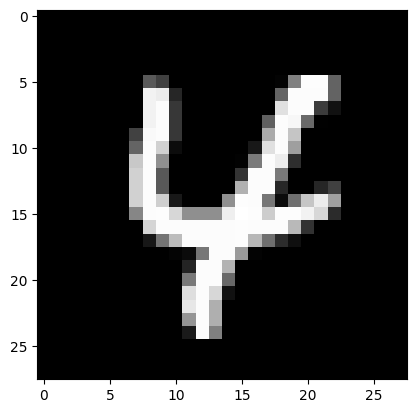

Prediction: 7
Label: 7


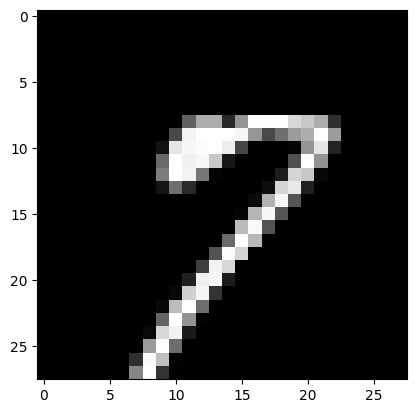

Prediction: 8
Label: 8


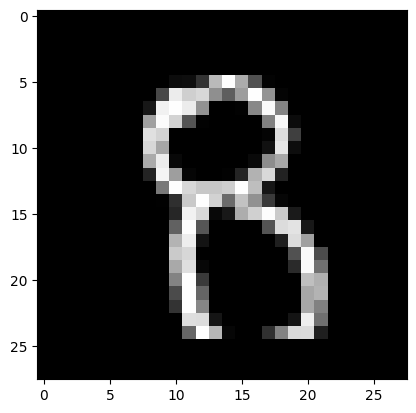

In [9]:
test_prediction(49, W1, B1, W2, B2)
test_prediction(5, W1, B1, W2, B2)
test_prediction(110, W1, B1, W2, B2)

In [10]:
dev_predictions = getPredictions(
    forwardPropagation(W1, B1, W2, B2, X_dev)[3]
)

print("Dev accuracy:", getAccuracy(dev_predictions, Y_dev))

[4 0 6 1 4 9 5 9 8 8 2 4 4 9 1 6 4 0 3 2 9 2 2 3 6 3 7 5 7 7 1 7 1 1 2 1 2
 6 1 1 5 5 7 3 2 5 5 0 5 0 7 6 8 2 7 9 7 1 8 6 0 8 9 6 2 5 3 5 8 2 7 6 0 2
 1 6 0 3 1 3 7 6 7 0 8 3 7 3 5 5 6 1 1 6 6 1 8 4 6 2 8 1 2 9 4 3 0 4 8 6 3
 9 0 8 0 0 8 7 3 7 6 2 0 6 0 7 9 9 7 4 9 8 5 8 4 6 5 2 0 6 4 1 0 7 2 5 1 0
 7 5 6 4 1 1 8 9 2 0 7 7 7 1 8 2 6 1 1 1 6 5 8 1 8 7 5 6 3 8 0 0 1 4 7 9 9
 6 9 2 3 1 9 4 4 1 8 7 4 3 2 7 6 1 6 2 2 6 7 9 7 3 9 5 3 7 3 2 9 6 9 1 2 7
 5 3 0 8 4 3 3 0 4 8 3 7 9 3 1 8 8 7 7 8 6 6 5 7 7 8 5 2 7 6 1 1 1 7 5 1 1
 9 4 7 8 2 9 1 1 4 5 1 3 4 0 0 6 8 0 6 0 7 9 5 8 7 6 3 2 8 5 5 4 6 9 4 7 4
 2 2 2 2 1 9 9 3 8 8 3 2 5 0 5 4 3 3 9 1 5 5 2 0 4 3 1 8 2 4 8 7 9 3 6 7 6
 4 6 2 2 8 5 1 4 3 4 2 2 3 3 4 3 8 1 5 2 3 0 8 8 1 6 4 6 1 9 1 6 9 7 2 9 6
 5 9 1 4 0 8 0 8 6 0 1 0 1 2 5 8 4 3 4 5 0 4 0 6 3 0 2 8 7 2 8 6 5 7 8 3 1
 4 0 4 0 8 1 2 8 7 1 9 5 1 3 7 2 4 6 8 0 6 3 1 7 6 0 5 6 7 1 3 6 7 2 2 9 4
 3 5 7 3 8 1 0 4 0 3 4 3 4 1 1 7 6 6 9 9 6 5 2 7 2 1 2 1 6 3 5 9 8 2 0 3 1
 8 9 1 1 1 1 3 2 9 2 9 0 

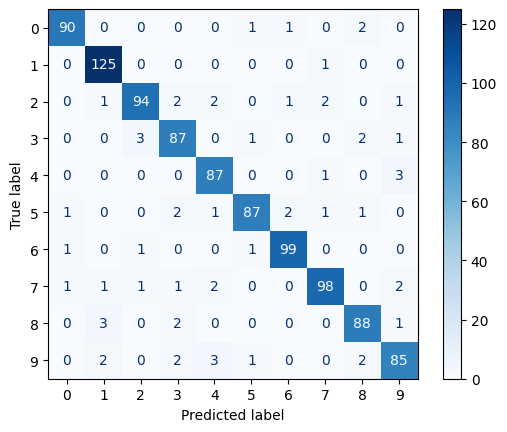

In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(Y_dev, dev_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(cmap="Blues")
plt.show()